# 06-Dify工作流与Agent：电商问答和NLP2SQL助手

本篇对应课程第 6 章《工作流与 Agent》，先区分工作流和 Agent，再学习 Dify 的 Workflow、Chatflow 和节点编排，最后整理两个案例：电商知识问答助手与 NLP2SQL 数据库查询助手。

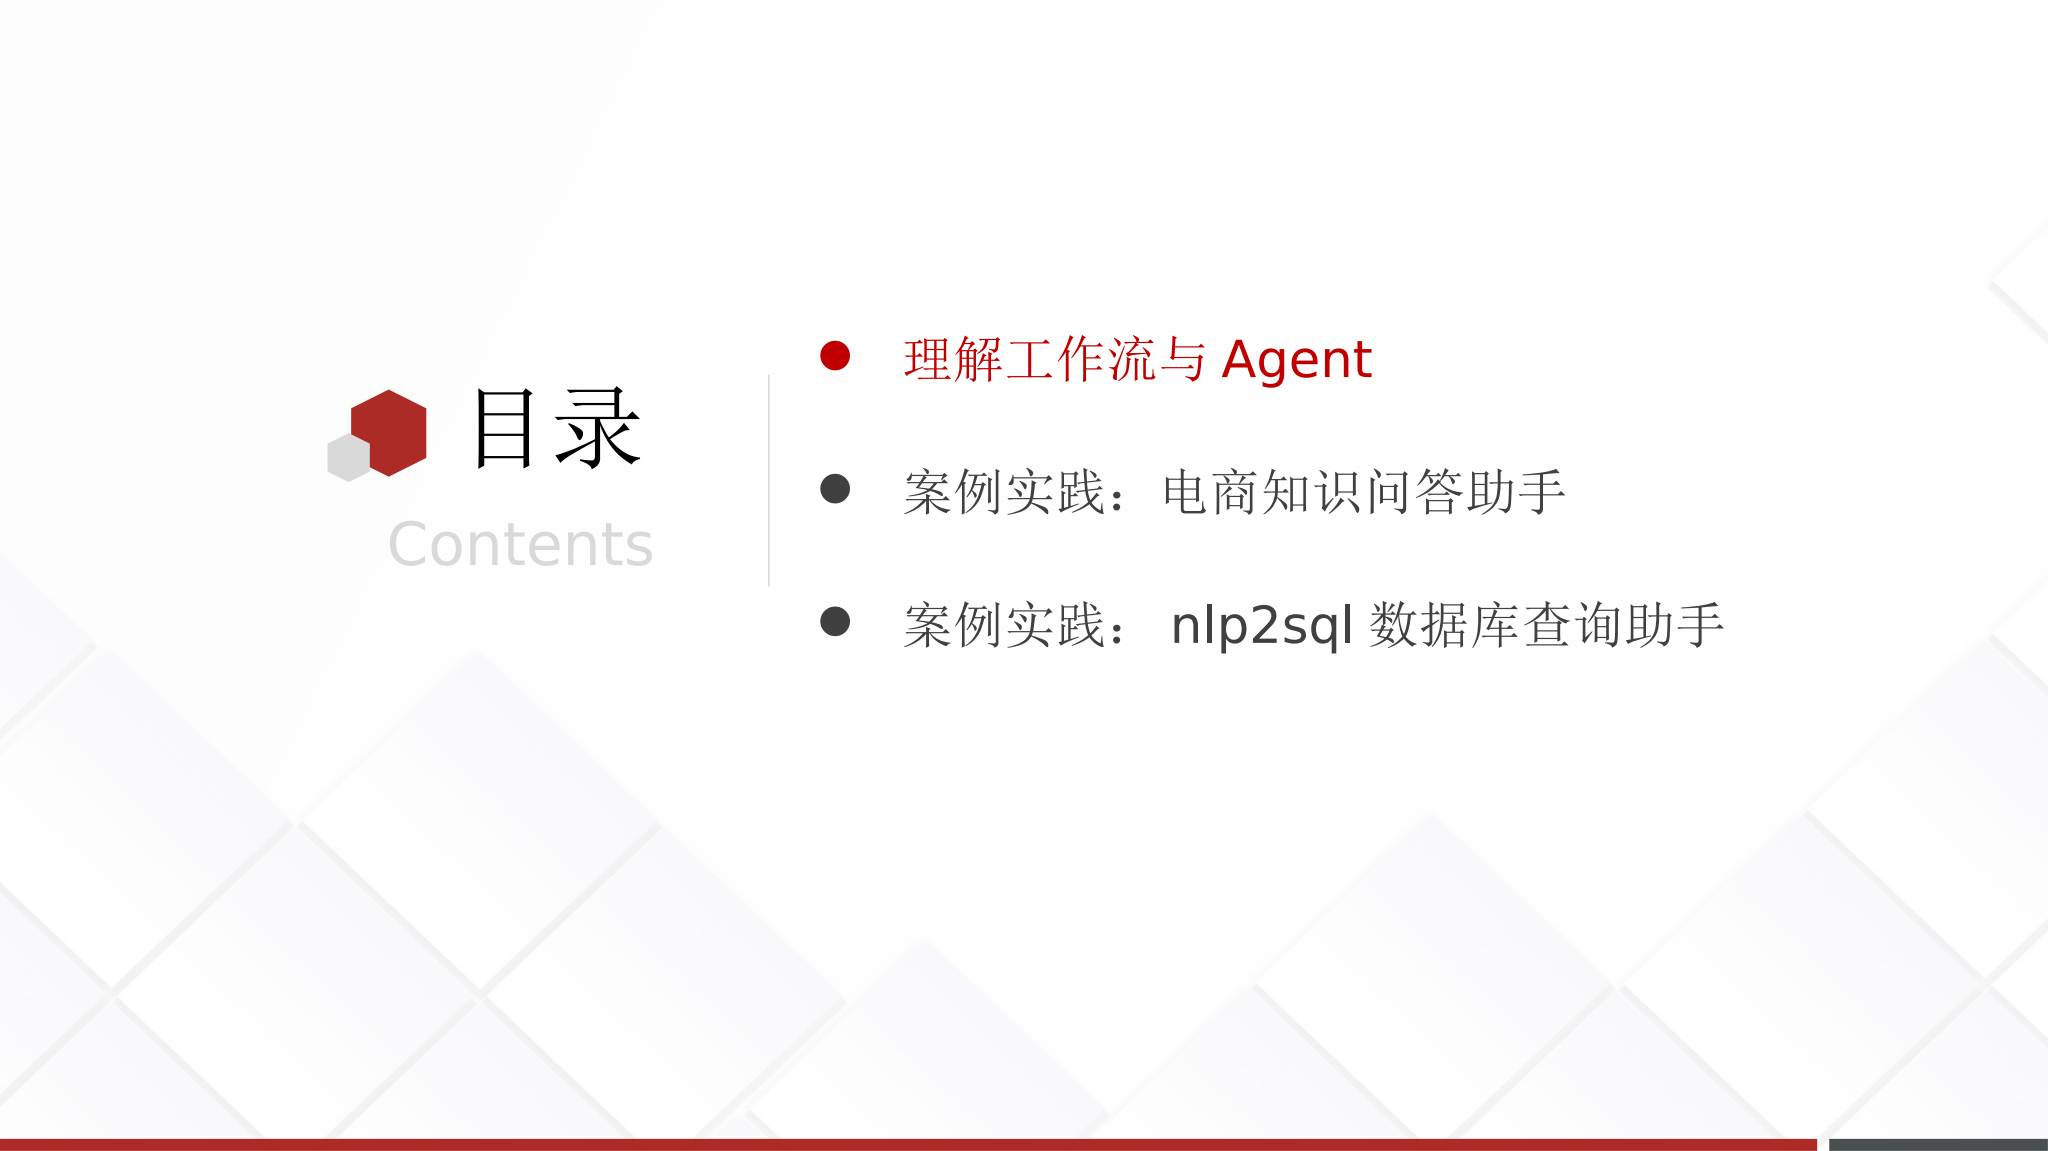


## 1. 什么是工作流

工作流是业务逻辑的可视化执行方式。它把一个复杂任务拆成一系列可管理的步骤，再通过图形化画布把这些步骤按顺序或按条件连接起来。

单一任务可以直接使用一个插件，例如查询天气；复杂任务则需要多个步骤协作，例如旅行规划、知识检索和数据分析。

工作流的价值在于路径清晰：开发者可以看到每个节点、输入、输出和分支，便于测试和定位问题。

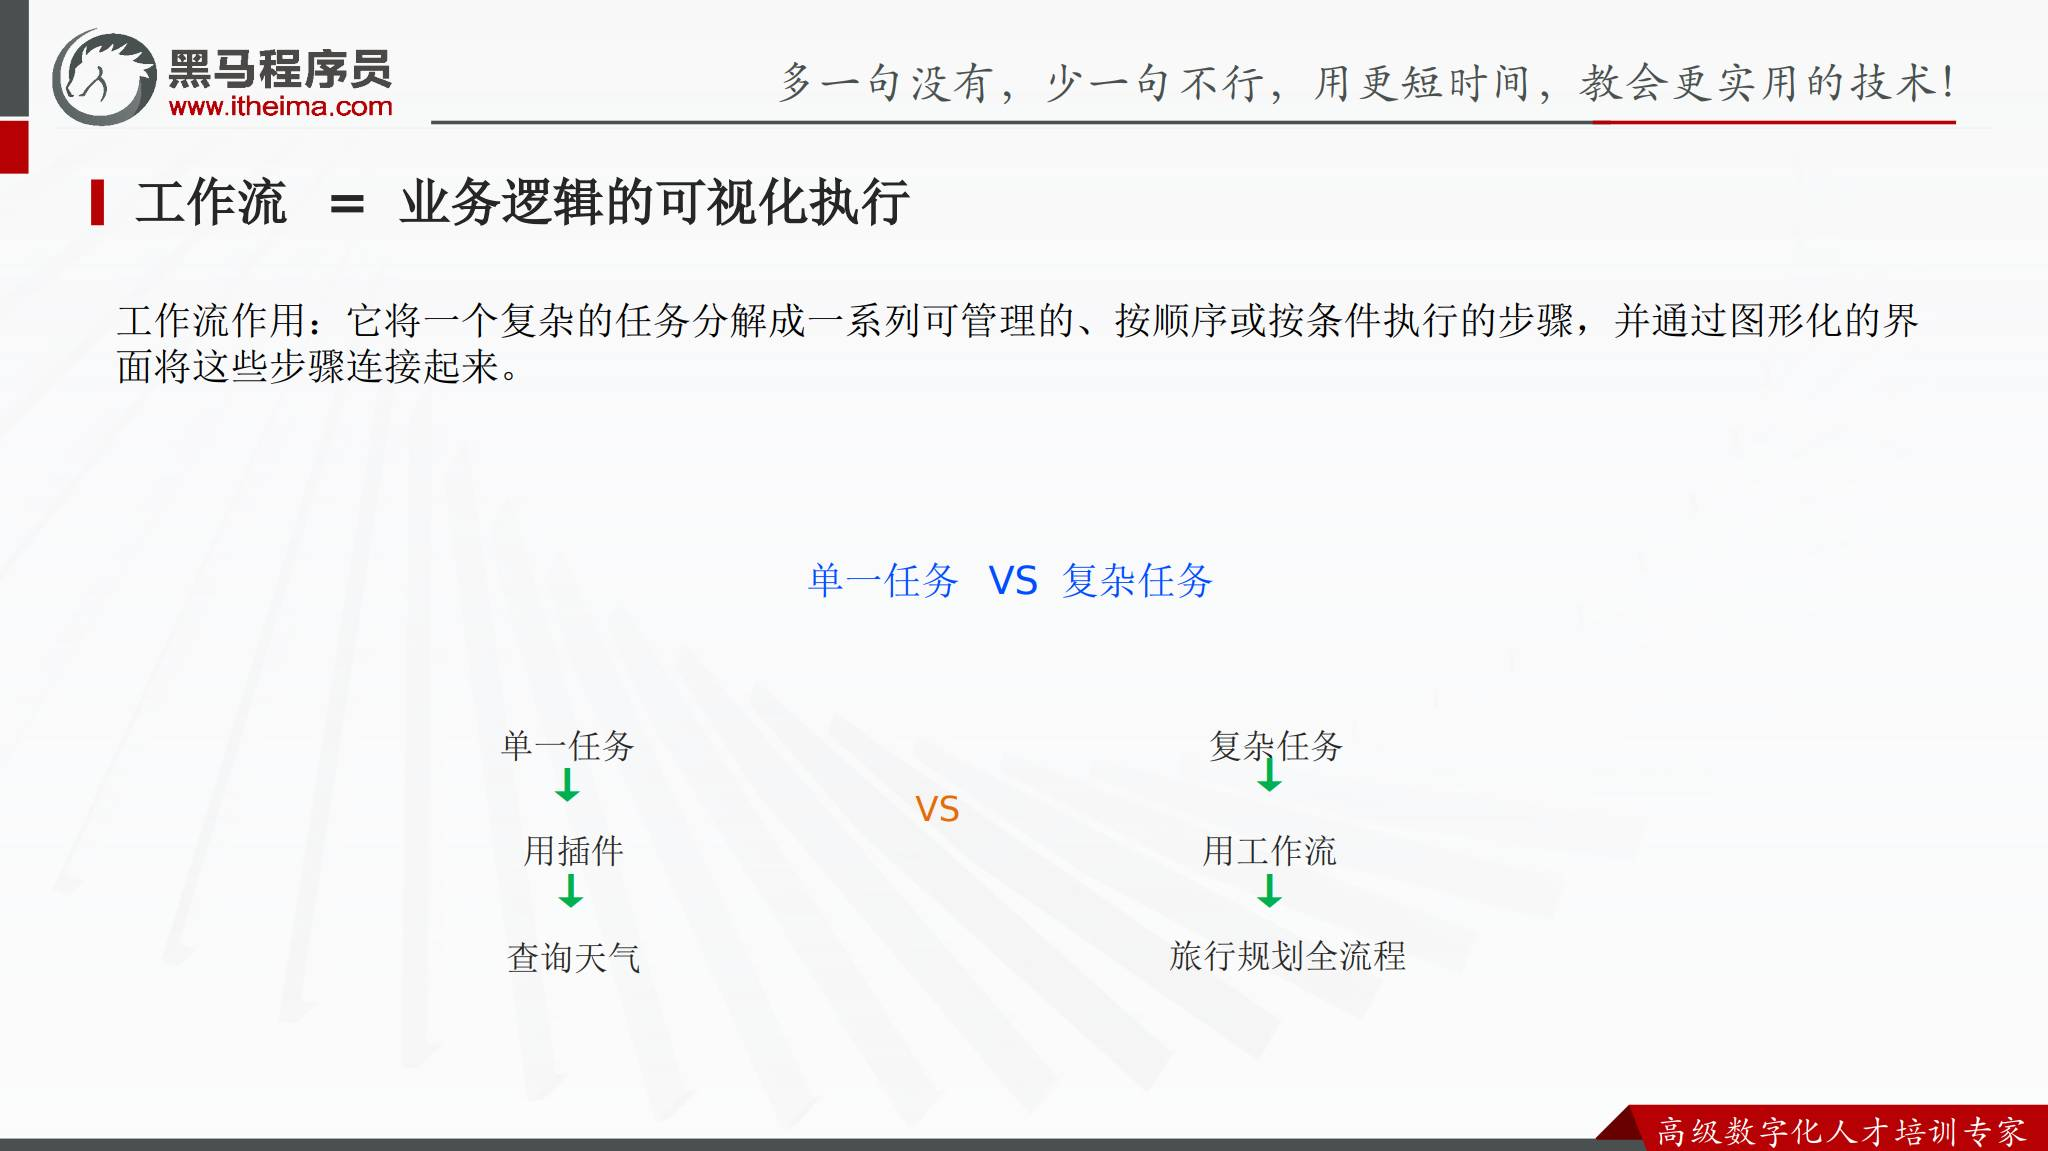


## 2. 什么是 Agent

Agent 是能够自主决策的 AI 助手。课件用 ReAct 形式概括它的运行方式：

```text
思考 → 行动 → 观察 → 再思考 → ……
```

Agent 的主要能力包括：

- **自主规划**：根据目标和环境反馈动态制定执行计划。
- **工具选择**：灵活调用 API、数据库和搜索等外部工具。
- **推理能力**：进行多轮思考并尝试自我纠错。

Agent 的智能化程度较高，但多轮推理会带来更多 Token 消耗和响应延迟，调试也比固定路径的工作流困难。

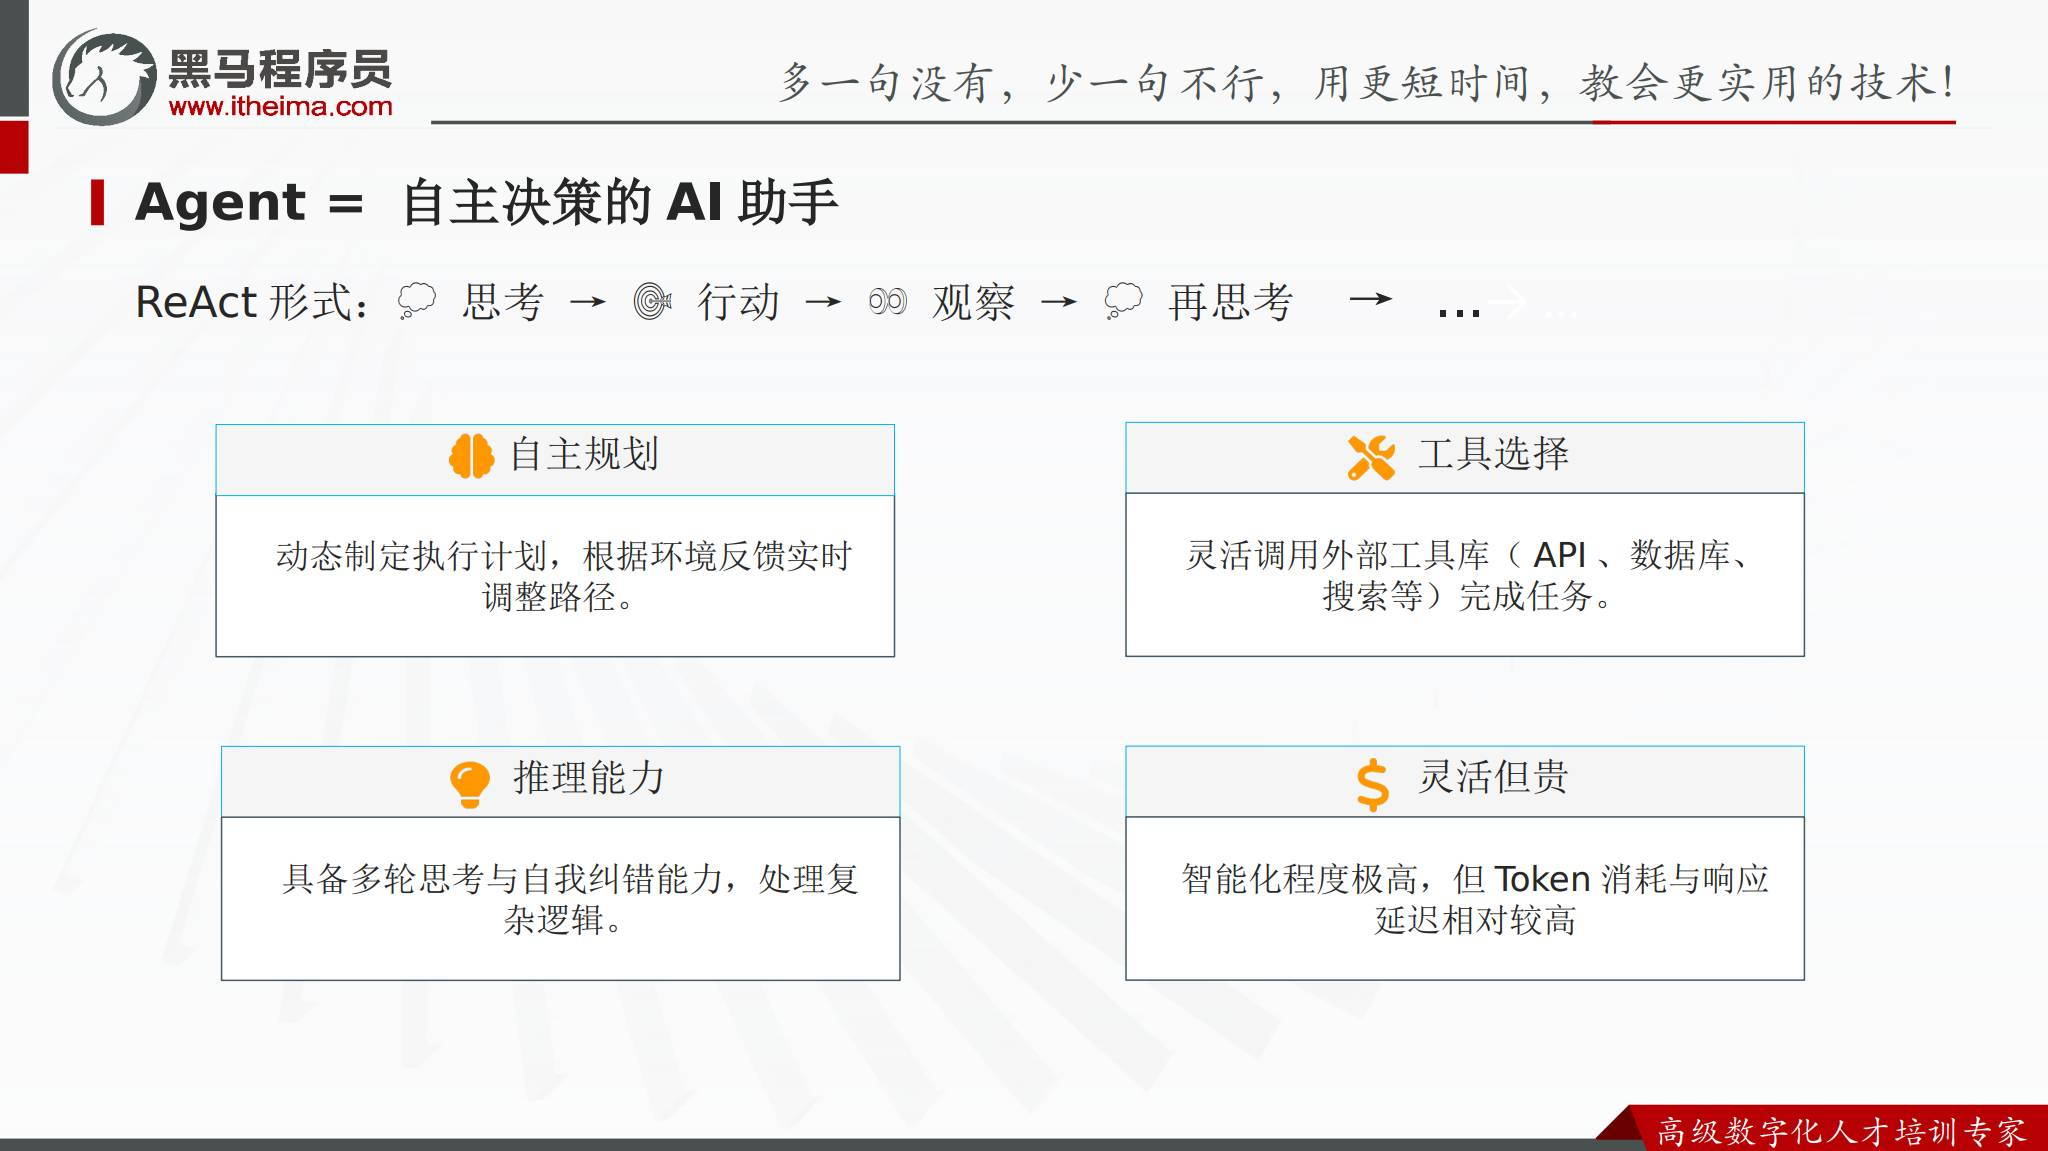


## 3. 工作流与 Agent 的关系

工作流和 Agent 不是互相排斥的两种技术。课程给出的核心观点是：**工作流是确定性的 Agent 实现方式**。

| 对比维度 | 工作流 | Agent |
| --- | --- | --- |
| 流程控制 | 固定不变，开发者显式定义 | 自主决策，动态规划 |
| 可预测性 | 高，路径清晰 | 相对较低，存在模型决策 |
| 灵活性 | 中等 | 高 |
| 运行成本 | 较低，Token 消耗可控 | 较高，多轮推理消耗更多 Token |
| 调试难度 | 较容易 | 较困难，部分决策像黑盒 |

选择哪种方式，取决于任务是否需要固定步骤、动态选择和自主规划。

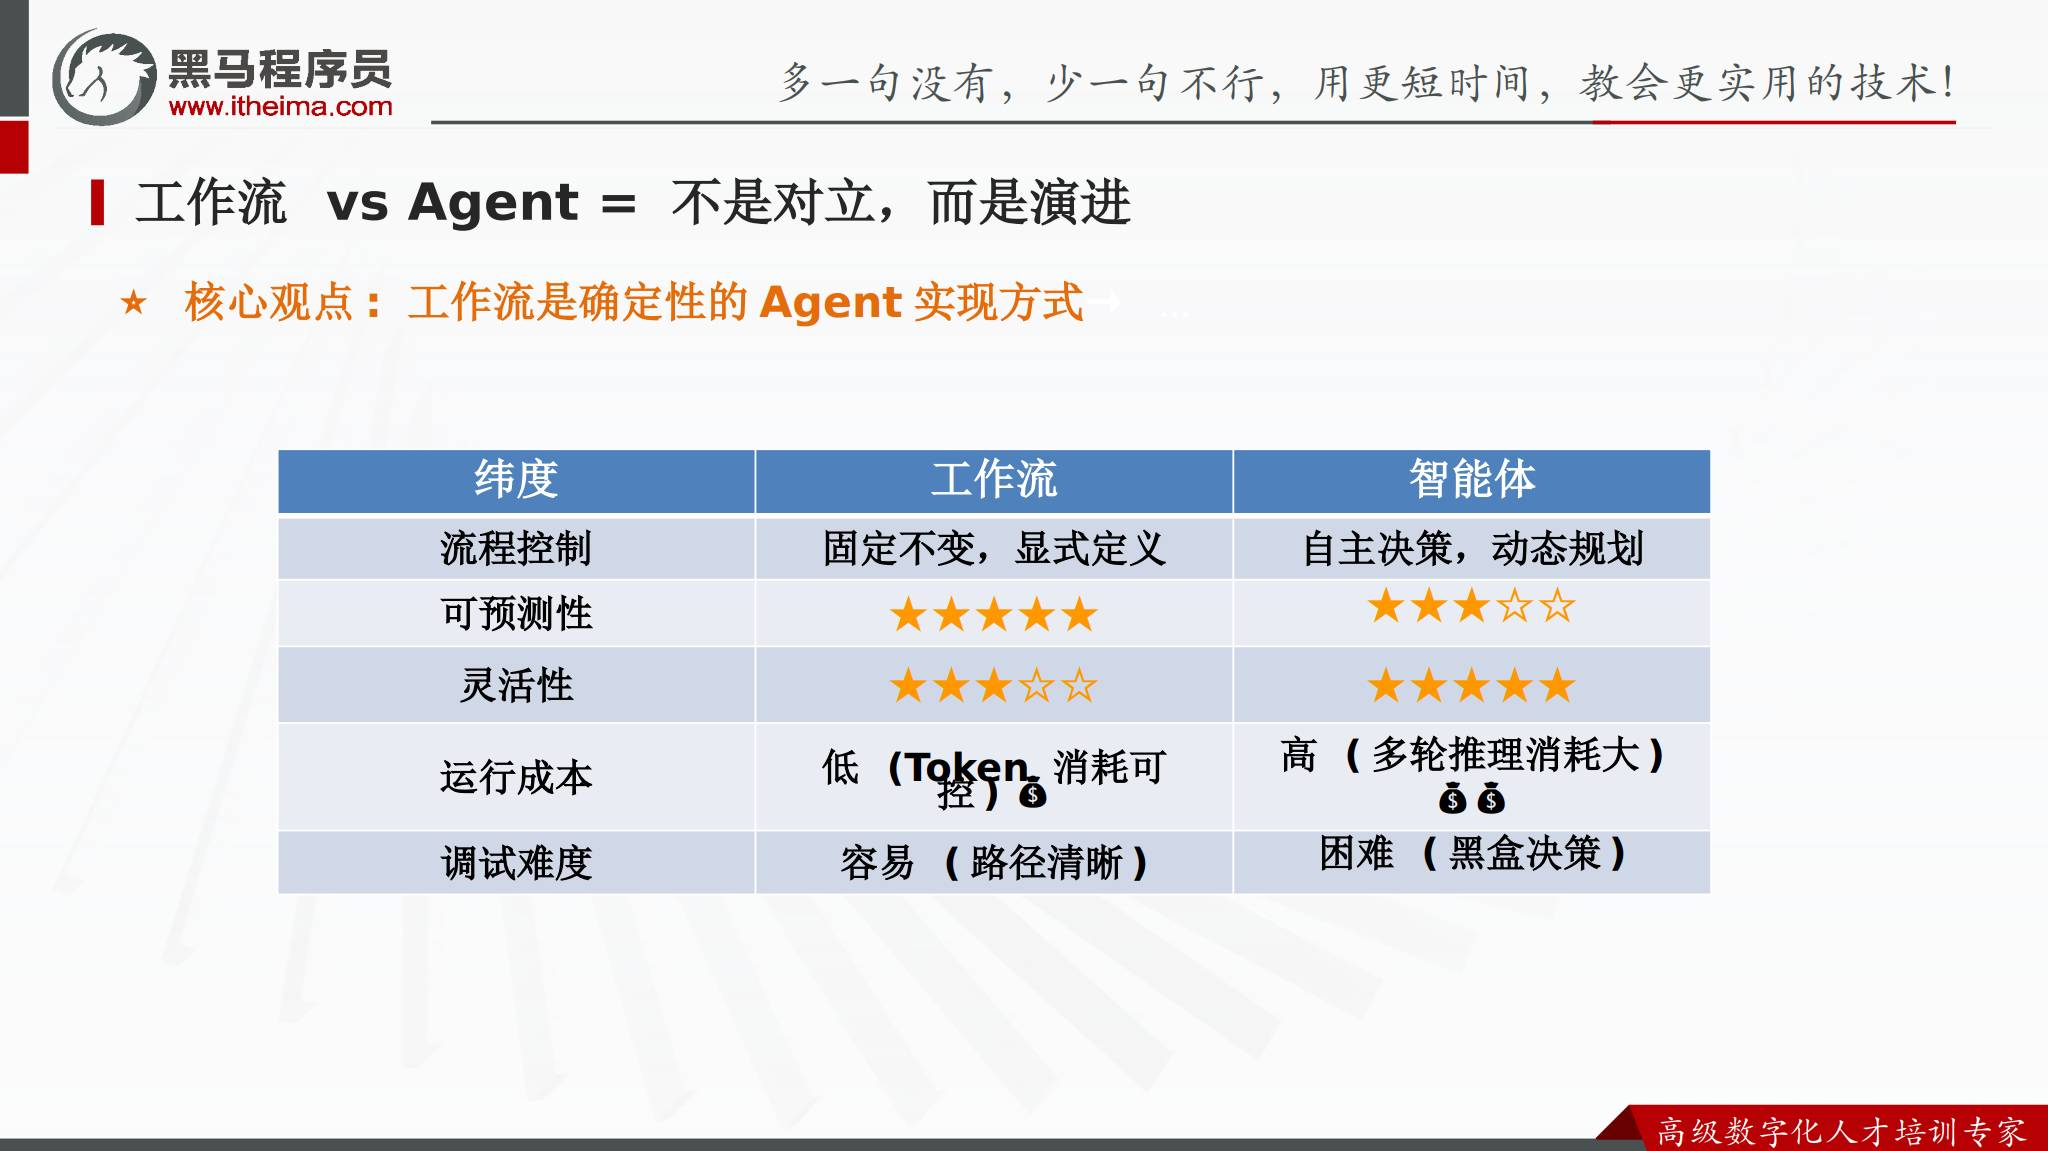


## 4. Dify 的两种工作流类型

Dify 提供 Workflow 和 Chatflow 两种工作流形态：

| 维度 | 工作流（Workflow） | 对话流（Chatflow） |
| --- | --- | --- |
| 适用场景 | 功能类、数据处理 | 对话类、交互式应用 |
| 典型案例 | 报告生成、海报制作、数据分析 | 智能客服、AI 助手、虚拟伴侣 |
| 上下文 | 不支持对话历史 | 支持读取对话历史 |
| 会话管理 | 没有会话概念 | 必须传入会话名称 |
| 发布渠道 | 本地运行、发布 API、嵌入网站 | 本地运行、发布 API、嵌入网站 |

任务需要持续对话上下文时，优先考虑 Chatflow；任务主要处理一次输入并输出结果时，可以使用 Workflow。

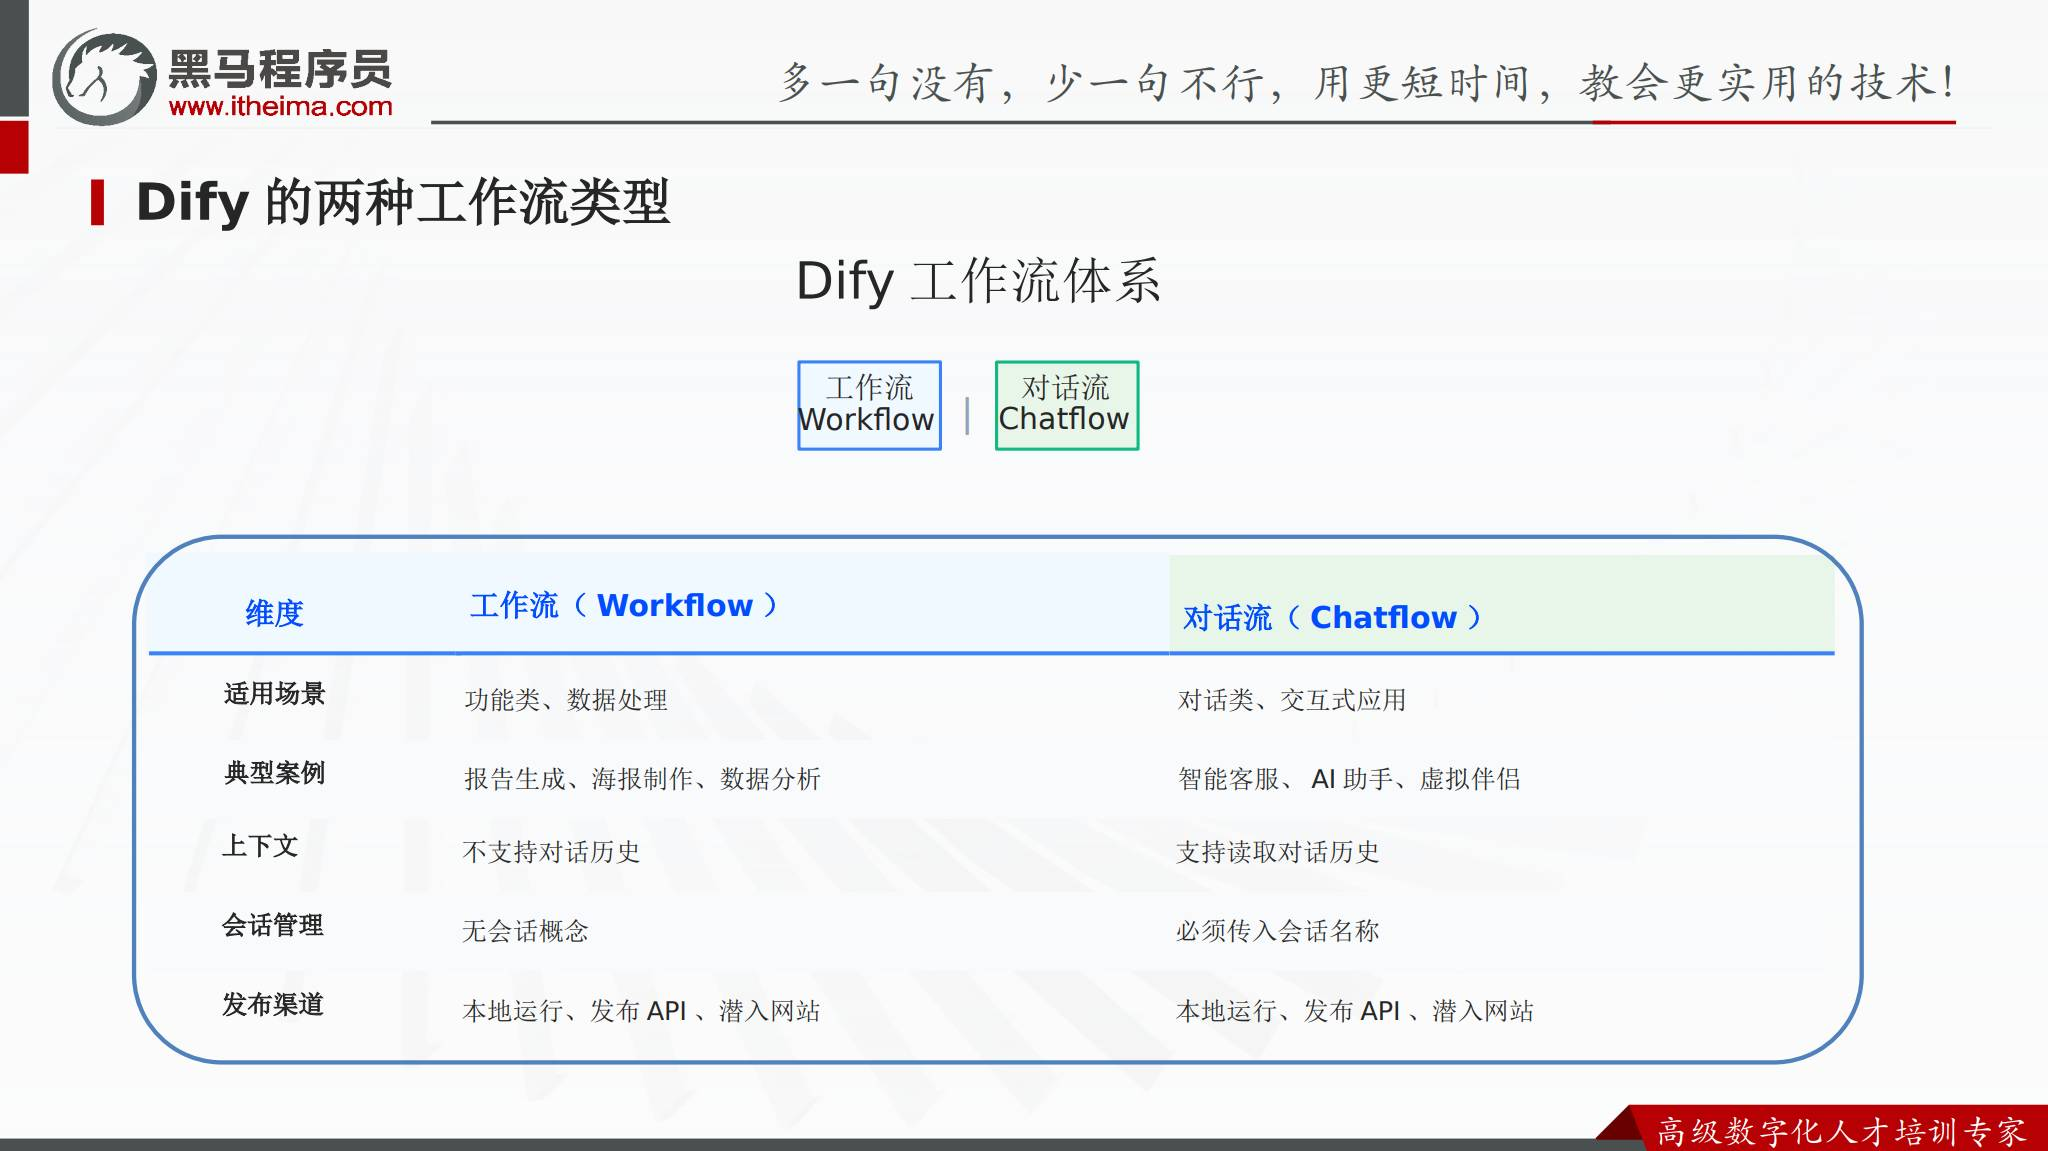


## 5. 创建工作流的标准流程

课件将创建工作流分成三个阶段。

### 创建应用

选择“创建空白应用”，再选择 Workflow 或 Chatflow。为应用设置清晰明确的名称和功能描述，帮助开发者和模型理解应用用途。

### 编排工作流

在可视化画布中添加节点，连接节点形成数据流，并配置每个节点的输入输出参数。课件列出的核心节点包括开始节点、LLM 节点、工具节点和结束节点。

### 测试与发布

点击测试运行，输入测试数据，检查每个节点的运行状态。测试通过后点击“发布”，发布后的工作流可以提供给其他用户使用。

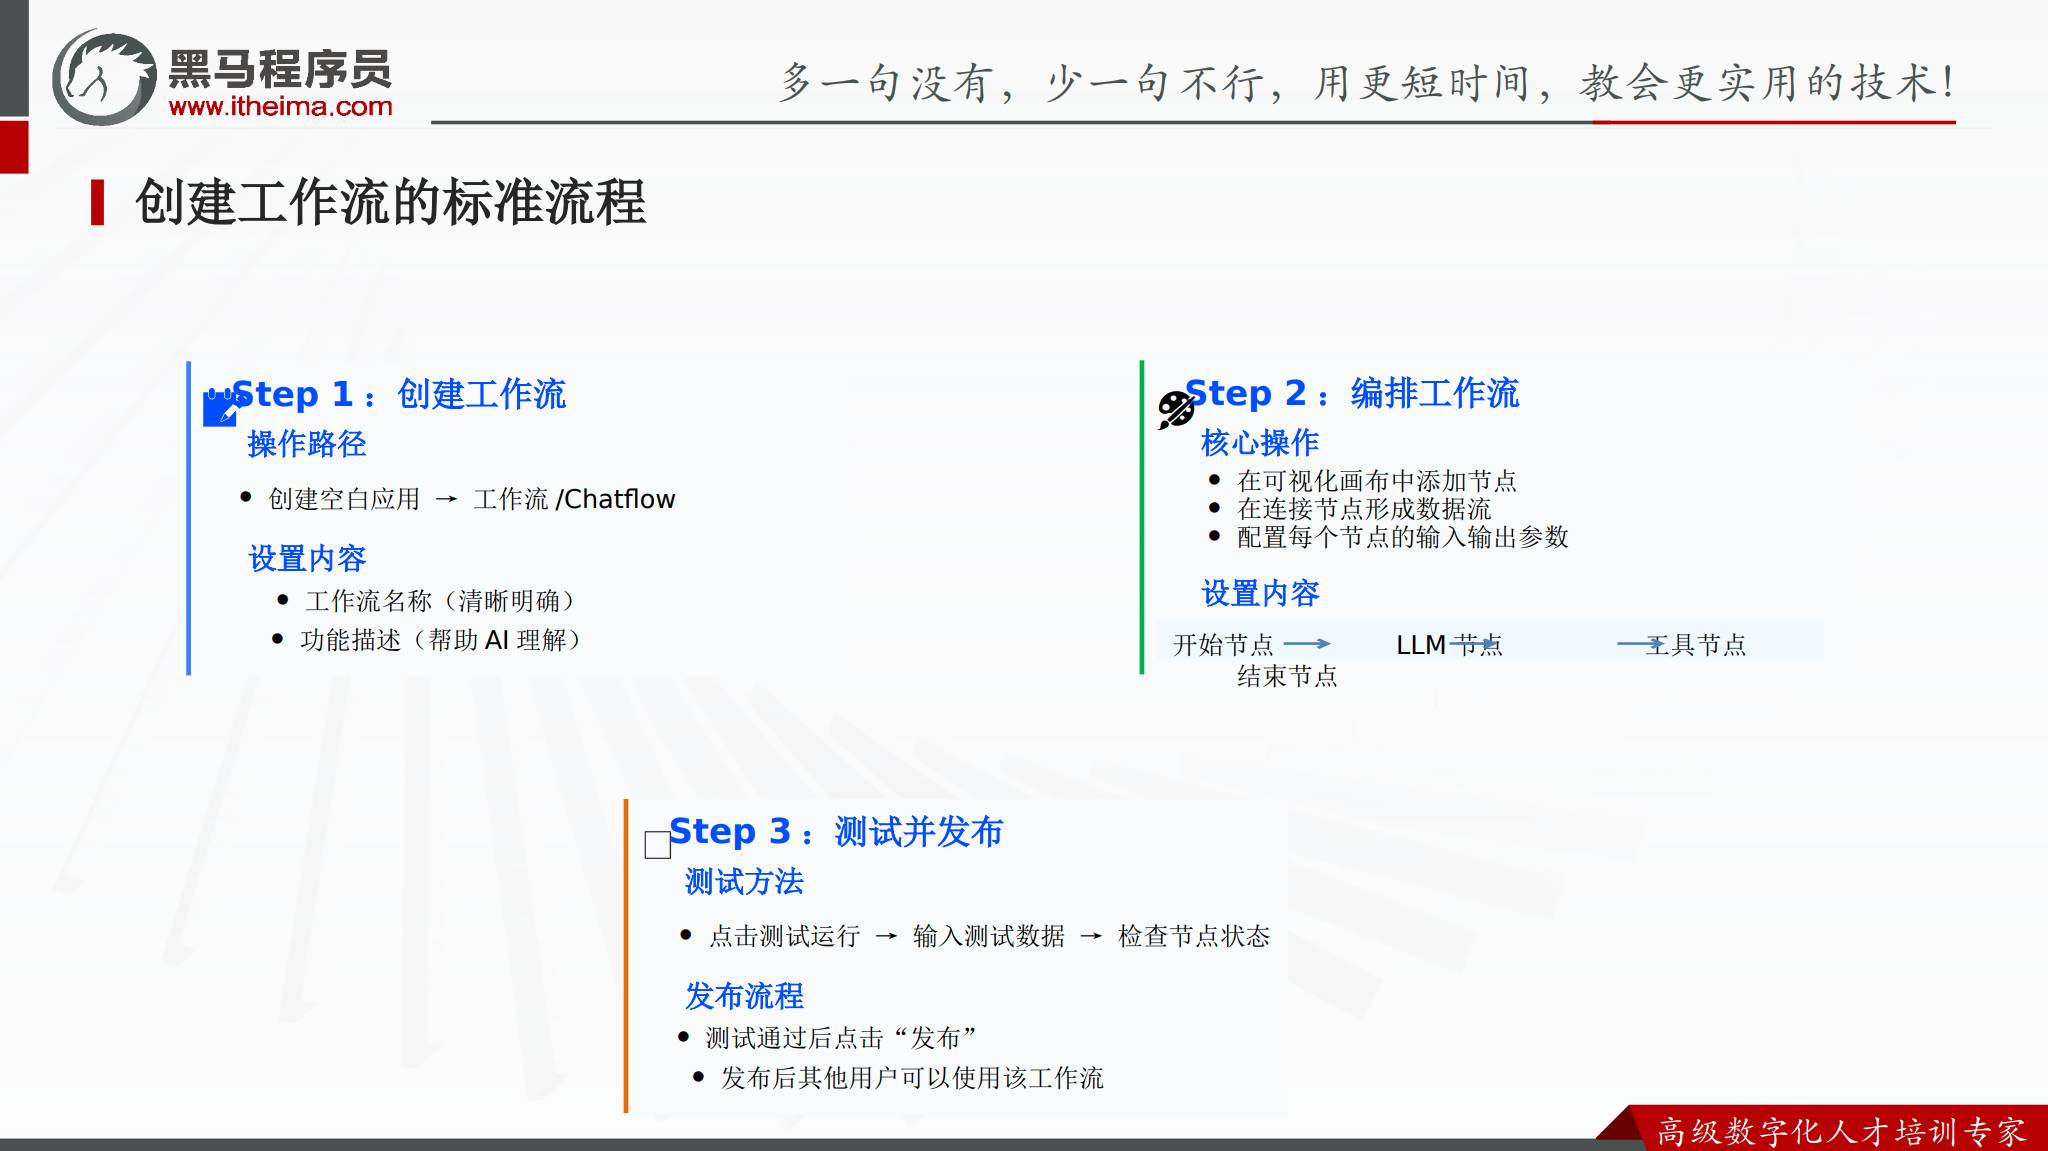


## 6. 工作流的核心组件

节点是工作流中的独立组件，负责处理数据或执行任务。不同节点通过输入和输出连接起来，形成完整的数据流。

常见节点职责如下：

| 节点 | 作用 |
| --- | --- |
| 开始节点 | 接收用户输入或工作流初始参数 |
| LLM 节点 | 调用大模型进行理解、分类、生成或判断 |
| 工具节点 | 调用知识库、插件、数据库等外部能力 |
| 条件或分支 | 根据判断结果选择不同路径 |
| 结束节点 | 汇总结果并返回给用户或下游系统 |


## 7. 第一案例：电商知识问答助手

这个案例面向课程学习中的常见问题：课程内容多，记不住关键点；遇到问题时老师不一定在线；自己搜索效率低；网上资料质量不一致，难以判断。

核心需求是：

- 掌握课程内容，随时解答课程相关问题。
- 能够查找最新资料，补充课程外知识。
- 回答友好、详细、容易理解。
- 全天在线，随时提供帮助。

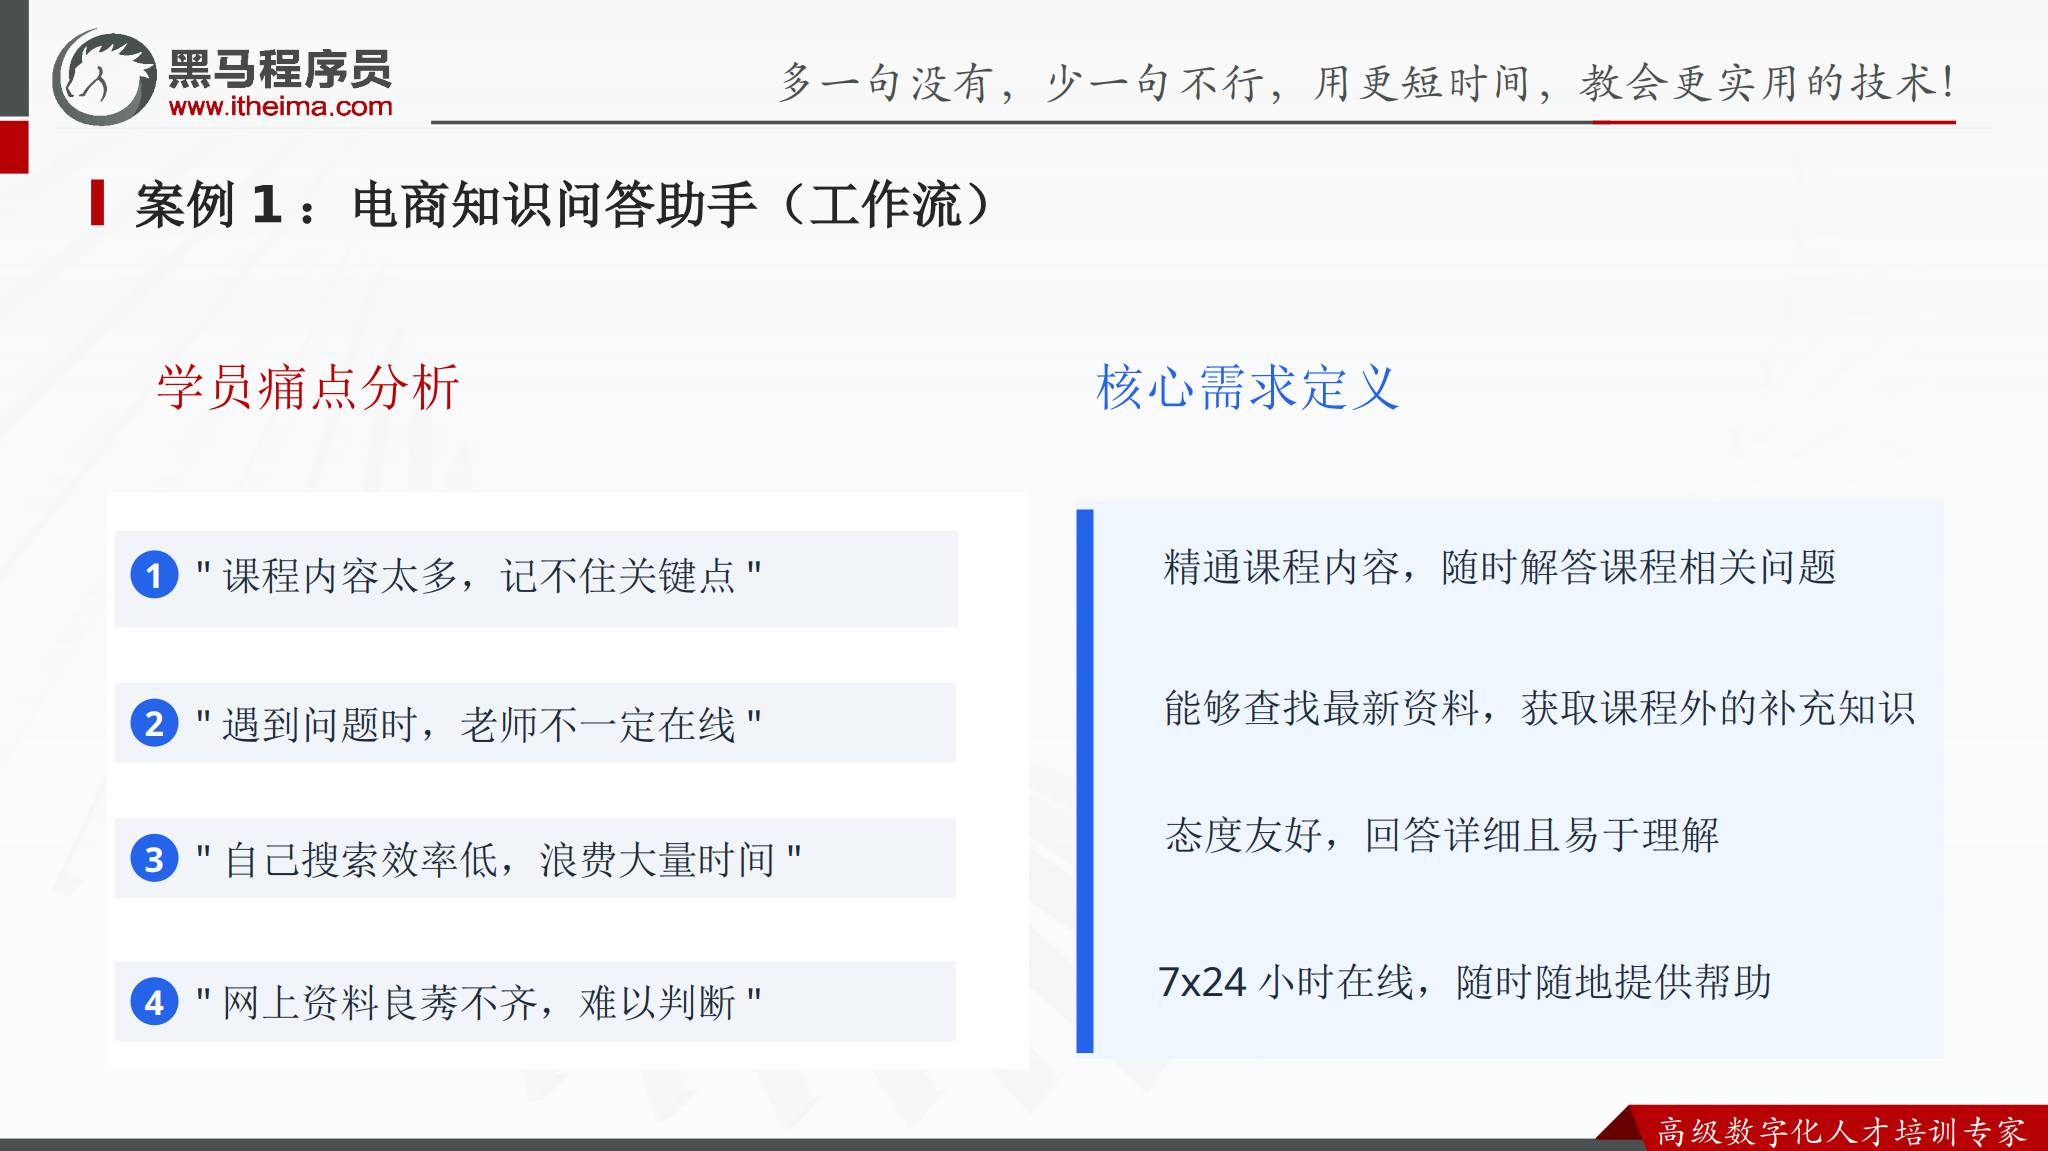


## 8. 电商问答助手的工作流

课件给出的基本流程是：

```text
开始节点
   ↓
意图识别
   ├─ 打招呼 / 找人工 → 直接回复
   └─ 其他问题 → 知识检索
                    ├─ 找到上下文 → 基于 RAG 大模型回答
                    └─ 没找到上下文 → 基于闲聊大模型回答
                                      ↓
                                   结束节点
```

这个流程把简单请求和知识问答分开处理，也为检索失败保留了兜底路径。

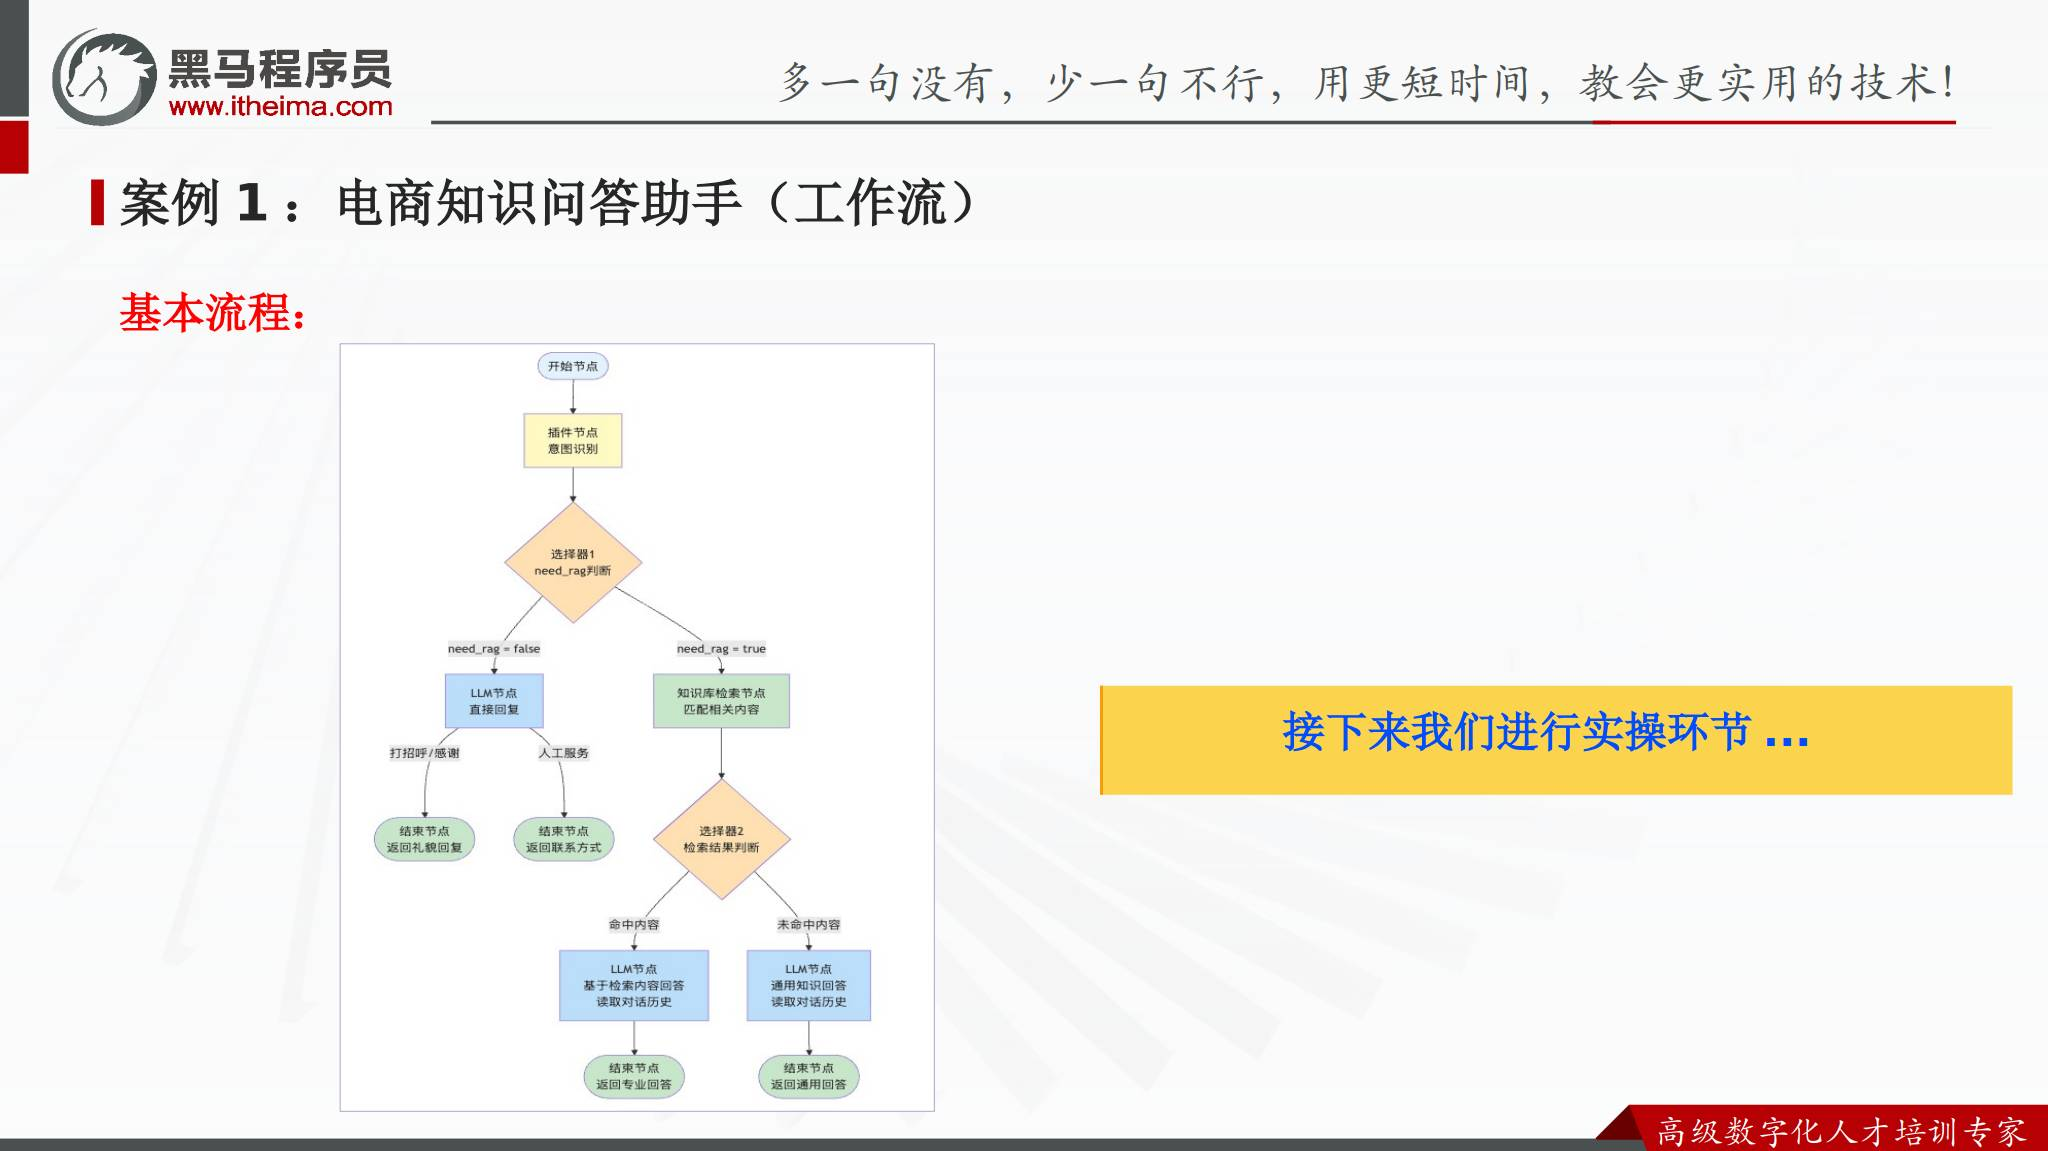


## 9. 电商问答流程中的关键判断

电商助手的核心不是把所有问题都交给同一个模型，而是先识别用户意图：

1. 用户输入进入开始节点。
2. 意图识别节点判断是否属于打招呼或找人工。
3. 如果是，直接返回对应结果。
4. 如果不是，进入知识检索。
5. 检索到上下文时，使用 RAG 大模型回答。
6. 没有检索到上下文时，使用闲聊大模型回答。
7. 结果进入结束节点。

通过分支，应用可以为不同问题选择更合适的处理路径。

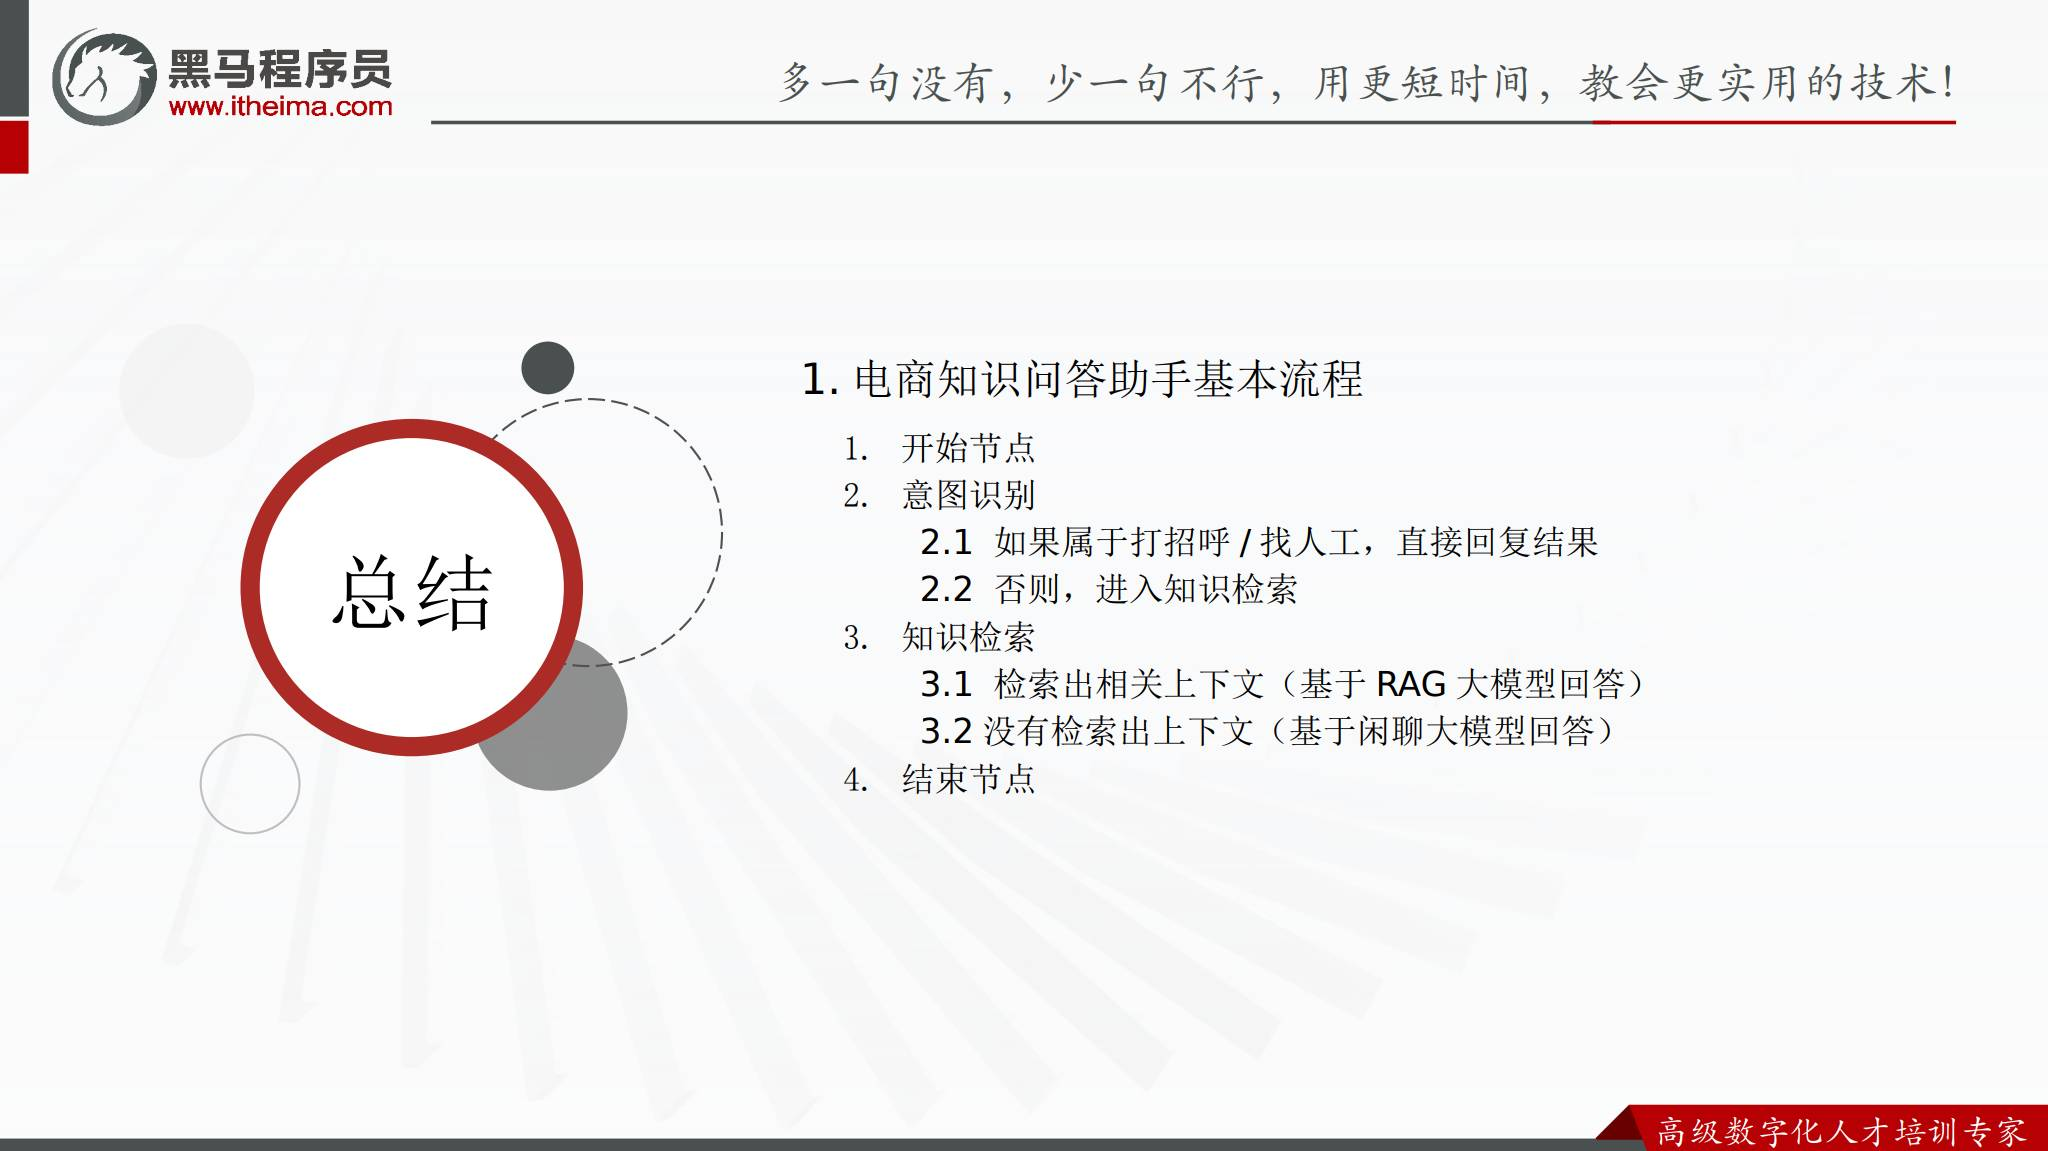


## 10. 第二案例：NLP2SQL 数据库查询助手

第二个案例面向教育管理场景。传统查询中，教师想查班级成绩，需要找数据部门等待；不会写 SQL 时，数据分析依靠人工统计；不同班级横向比较也费时且容易出错。

核心需求是：

- 接受自然语言提问，自动转换为 SQL 并查询数据库。
- 快速输出各班成绩排名、均分对比等关键数据。
- 不要求教师掌握 SQL 基础。
- 全天在线提供查询帮助。

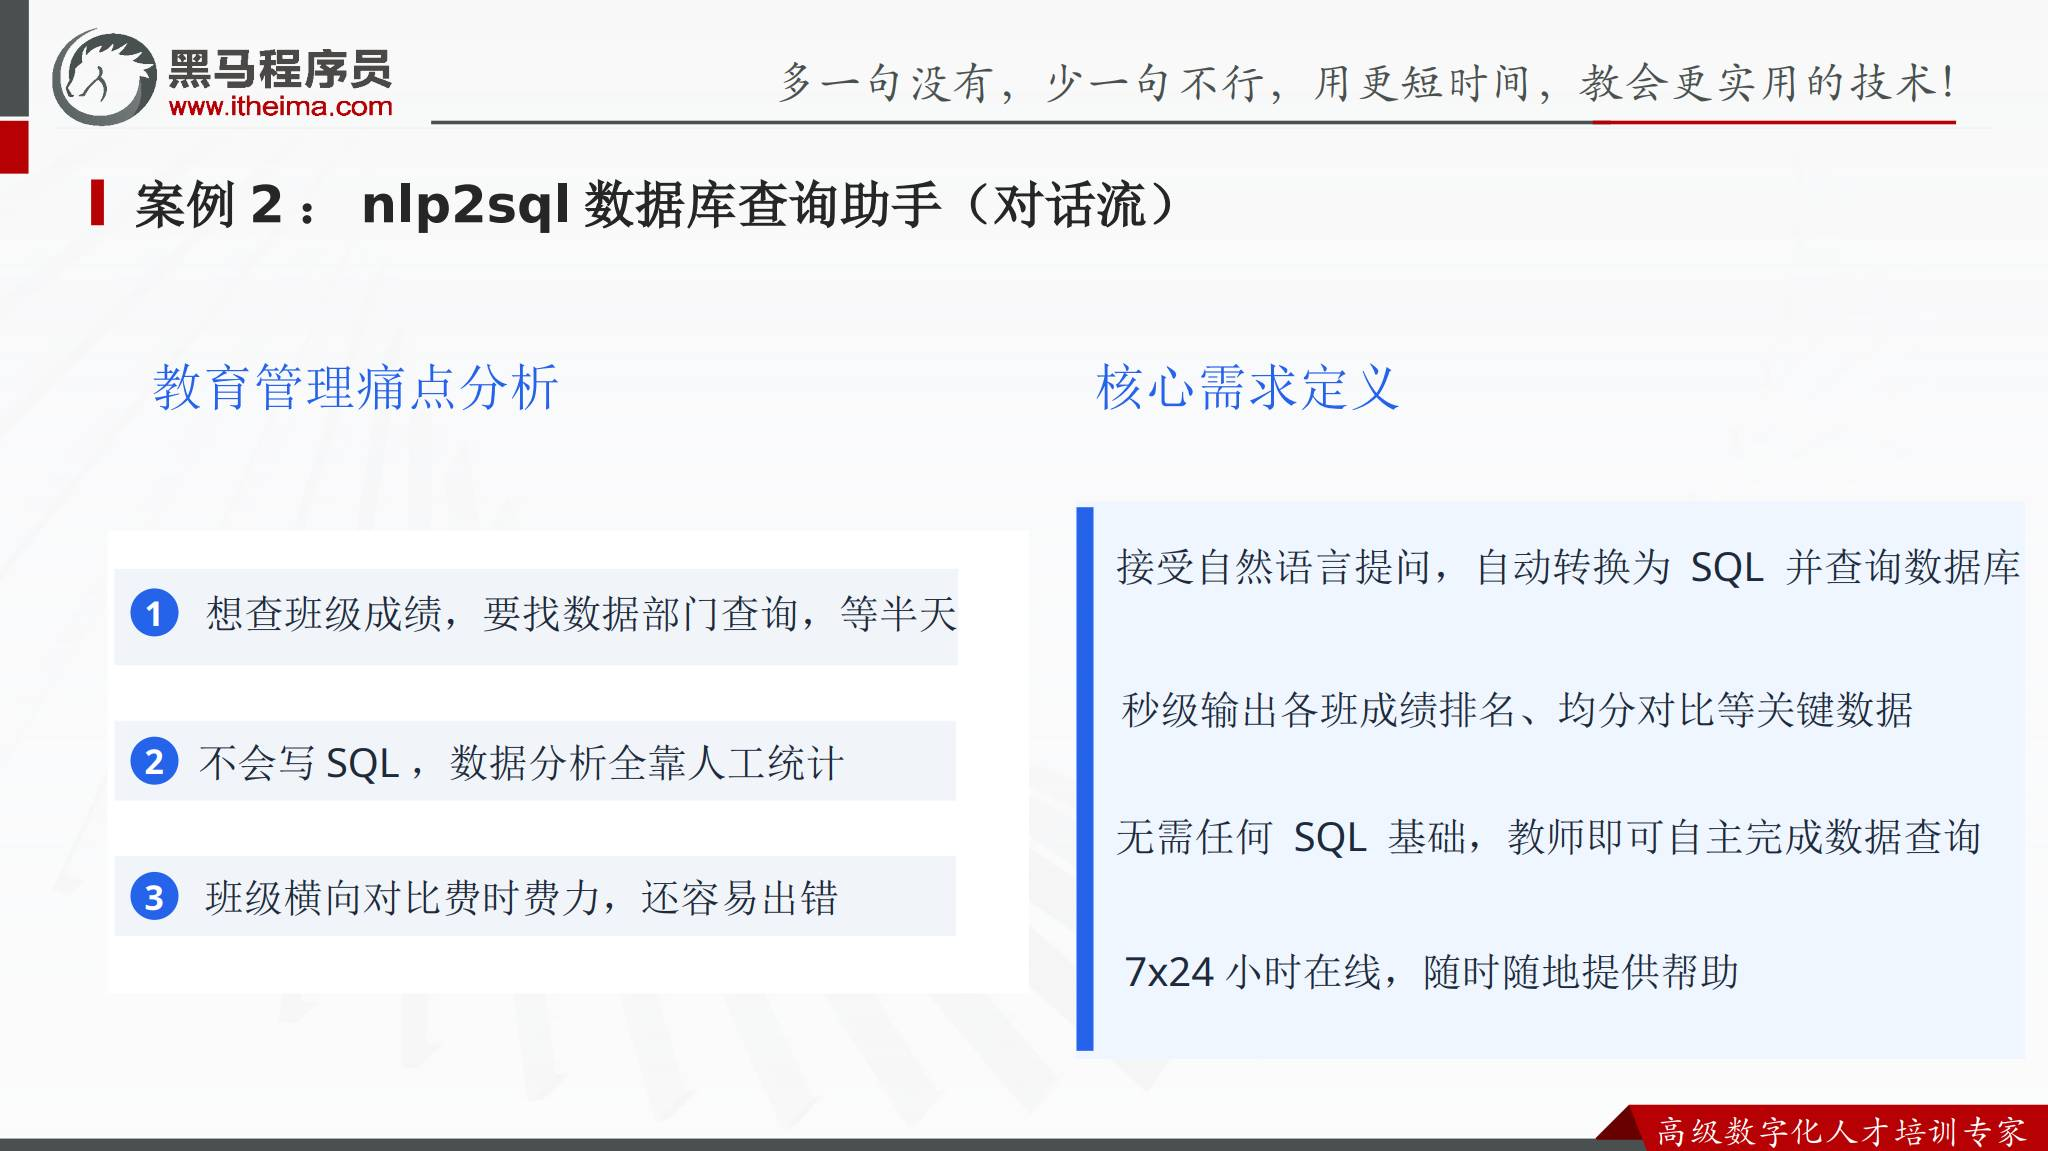


## 11. NLP2SQL 对话流

课件给出的基本流程是：

1. 用户输入自然语言问题。
2. 大模型根据问题生成 SQL 语句。
3. 通过 database 插件执行 SQL。
4. 大模型判断是否需要图表。
5. 如果需要，解析 ECharts 配置参数。
6. 展示查询结果。

这条流程把自然语言理解、数据库查询和结果可视化连接起来，用户不需要直接编写 SQL。

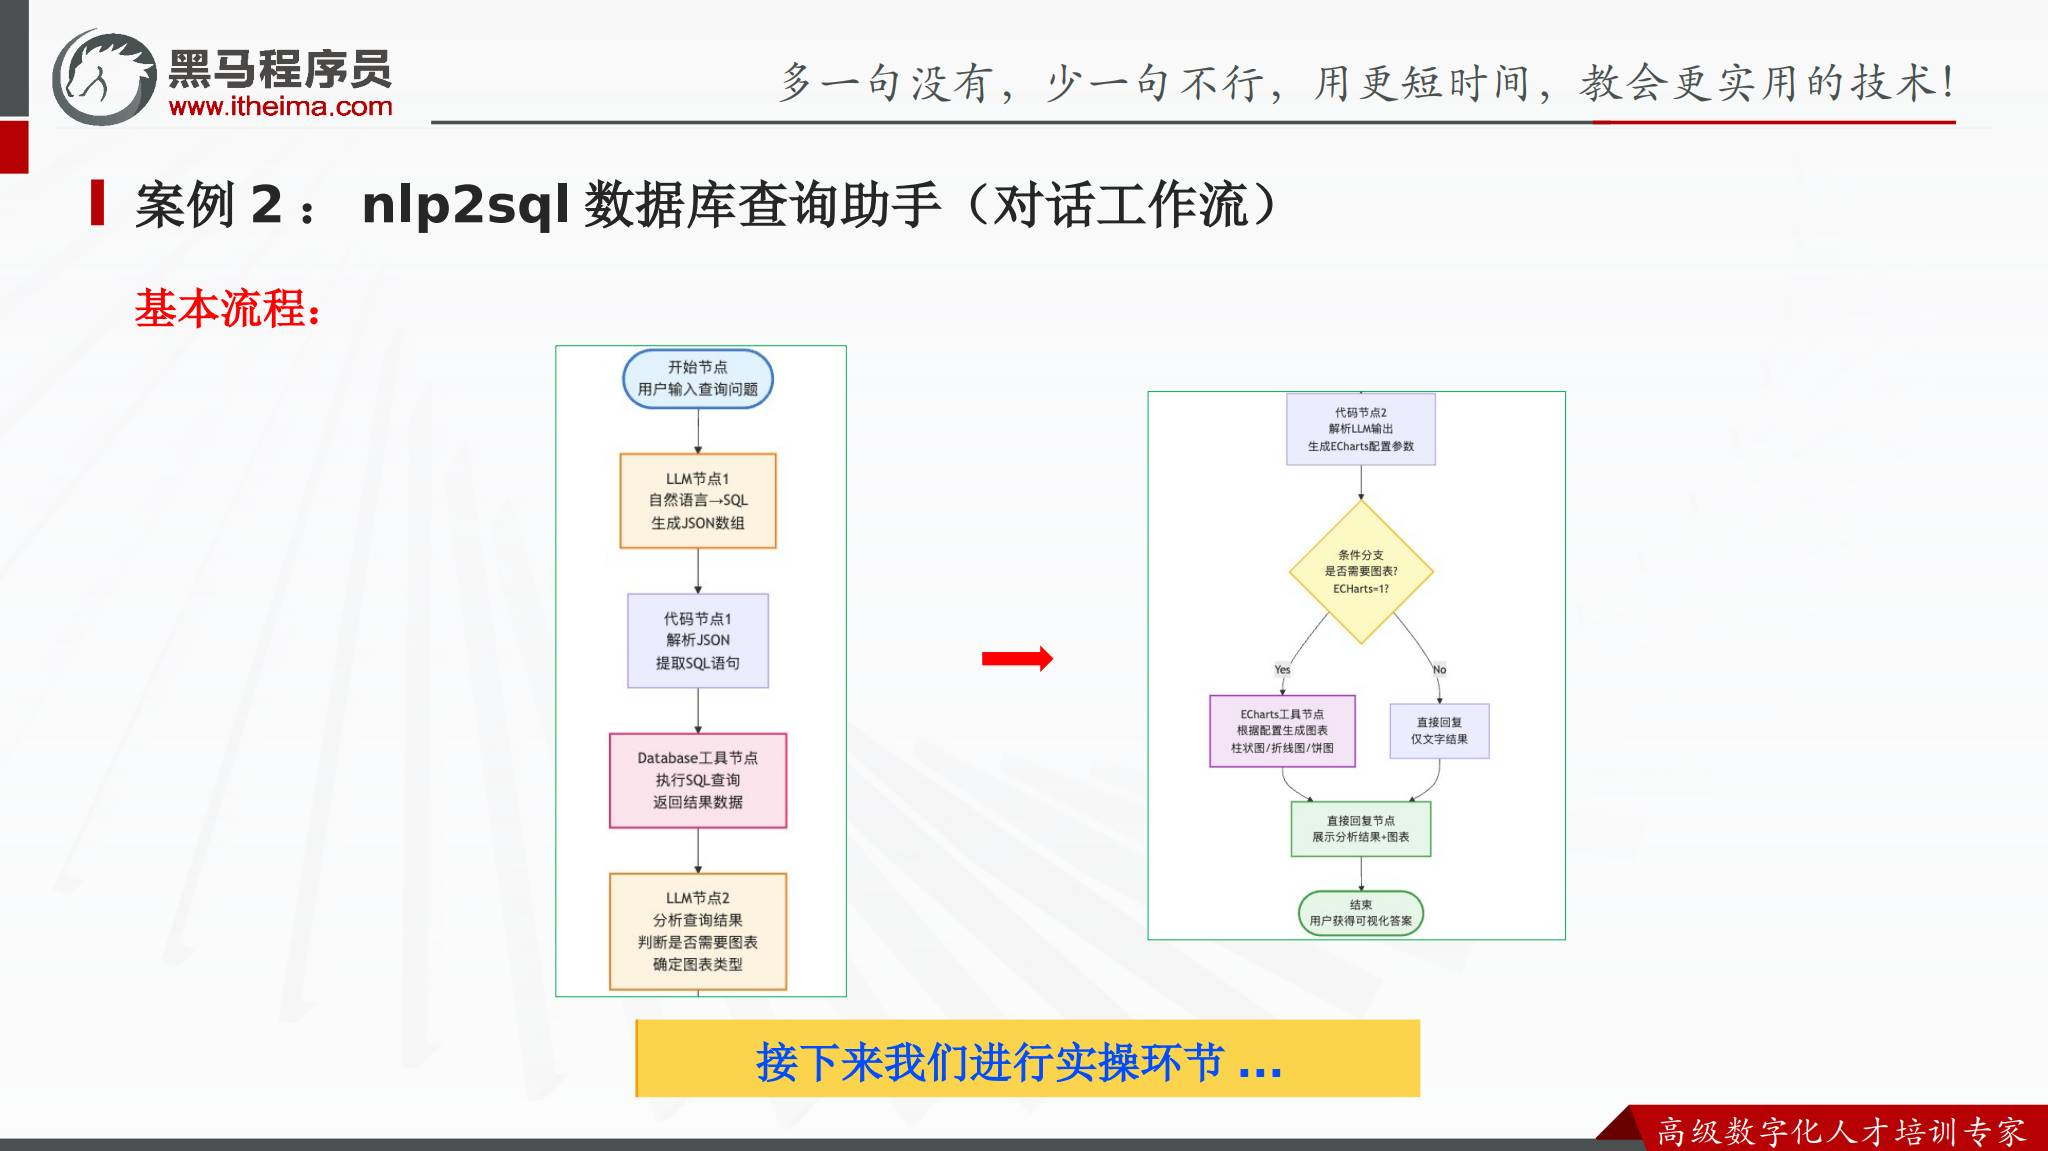


## 12. NLP2SQL 案例的边界

自然语言生成 SQL 时，应用需要把数据库结构、可查询字段和业务规则提供给模型。执行前还应检查 SQL 是否符合允许的操作范围，再把结果交给模型组织说明。

课件重点展示了“生成 SQL、执行 SQL、判断是否需要图表、展示结果”的流程。本篇不补写具体数据库表结构、连接配置或 SQL 模板，因为这些内容不在课件文字页中。


## 13. 两个案例的共同方法

电商问答和 NLP2SQL 虽然业务不同，但都遵循相似的工作流设计：

1. 开始节点接收输入。
2. LLM 节点理解问题或识别意图。
3. 根据判断结果选择知识库、数据库或其他工具。
4. 对工具结果进行进一步处理。
5. 结束节点返回用户可理解的结果。

固定步骤适合放进工作流，模型负责其中需要语言理解和判断的节点，工具负责检索和执行。


## 14. 本章小结

工作流把业务逻辑拆成可视化节点，Agent 则通过自主决策动态选择路径。Dify 提供 Workflow 和 Chatflow 两种工作流类型：前者适合功能和数据处理，后者适合需要对话历史的交互应用。

电商问答助手通过意图识别和知识检索完成分支回答；NLP2SQL 助手把自然语言转换为 SQL，调用数据库并根据需要展示图表。

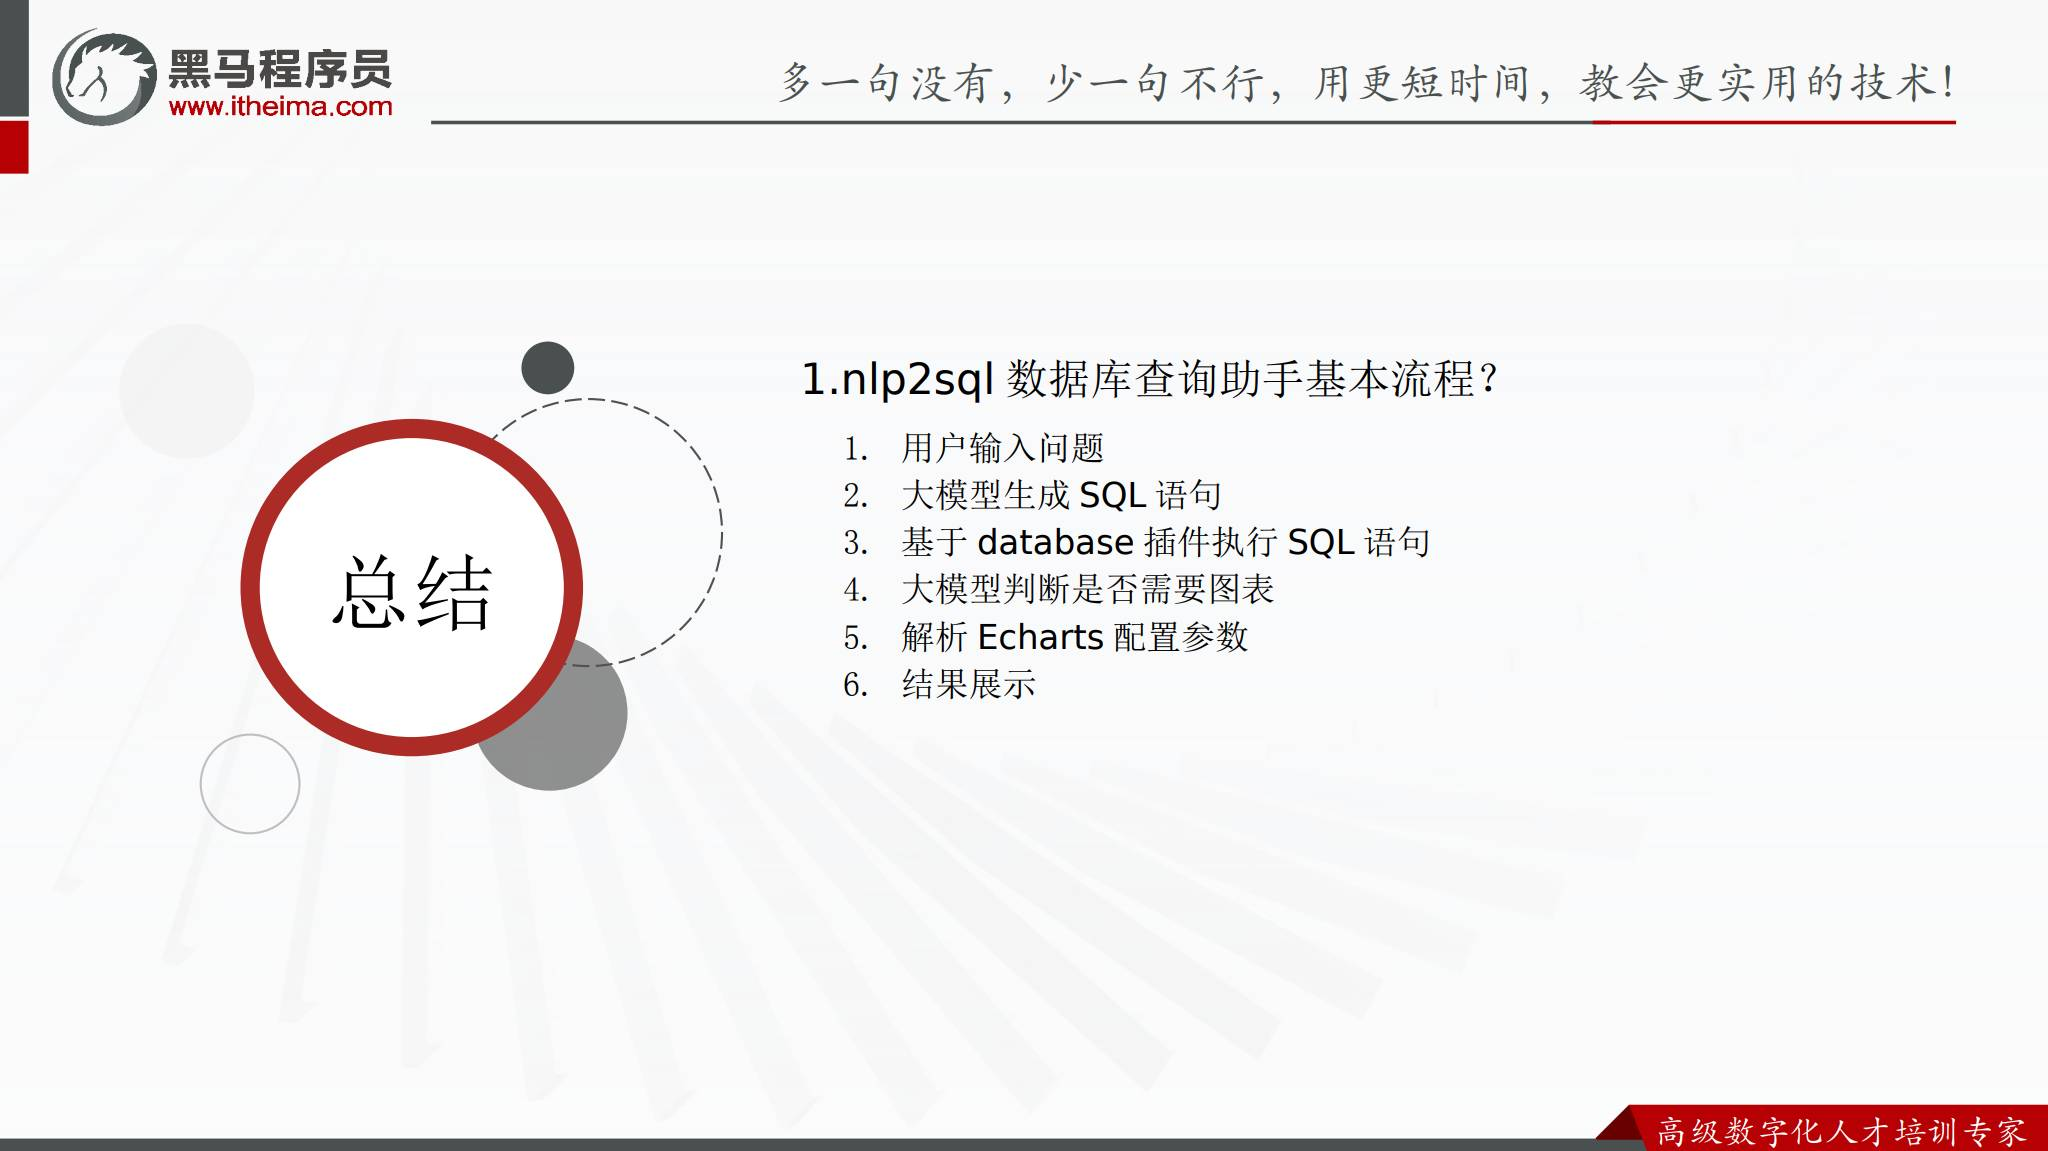


## 15. 资料边界

本篇依据第 6 章课件整理了工作流、Agent、Workflow、Chatflow、节点编排，以及两个案例的流程。课件没有提供完整的 Dify DSL、数据库结构、插件连接参数或 ECharts 配置，因此本篇保留架构和操作顺序，不虚构可直接运行的工程代码。
